In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
import sys

import xarray as xr
import cartopy.crs as ccrs
import cartopy.feature as cfeature

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

import pyproj
import cmocean

import numpy as np

import src.plotting as plot
import src.utils as utils
from src.config import *

In [3]:
AMOC_ON = "pi/pi-amoc-on"
AMOC_OFF = "pi/pi-amoc-off"

model_ice = "yelmo"

In [4]:
fpath = os.path.join(DIR_OUTPUT, AMOC_ON, "smb_GRL-16KM.nc")
ds_smb_amoc_on = xr.open_dataset(fpath, mode='r')

fpath = os.path.join(DIR_OUTPUT, AMOC_OFF, "smb_GRL-16KM.nc")
ds_smb_amoc_off = xr.open_dataset(fpath, mode='r')

# Basal mass balance
fpath = os.path.join(DIR_OUTPUT, AMOC_ON, "bmb_GRL-16KM.nc")
ds_bmb_amoc_on = xr.open_dataset(fpath, mode='r')

fpath = os.path.join(DIR_OUTPUT, AMOC_OFF, "bmb_GRL-16KM.nc")
ds_bmb_amoc_off = xr.open_dataset(fpath, mode='r')

In [5]:
ds_bmb_amoc_on

<xarray.Dataset> Size: 864MB
Dimensions:         (time: 100, month: 13, y: 182, x: 106)
Coordinates:
  * time            (time) float64 800B 10.0 20.0 30.0 ... 980.0 990.0 1e+03
  * month           (month) float64 104B 1.0 2.0 3.0 4.0 ... 10.0 11.0 12.0 13.0
  * y               (y) float64 1kB 0.0 16.0 32.0 ... 2.88e+03 2.896e+03
  * x               (x) float64 848B 0.0 16.0 32.0 ... 1.664e+03 1.68e+03
Data variables: (12/18)
    phi             (y, x) float32 77kB ...
    lambda          (y, x) float32 77kB ...
    t_bmb           (time, month, y, x) float32 100MB ...
    s_bmb           (time, month, y, x) float32 100MB ...
    t_freeze        (time, month, y, x) float32 100MB ...
    bmb             (time, month, y, x) float32 100MB ...
    ...              ...
    mask_ocn_lake   (time, y, x) int32 8MB ...
    mask_ice_shelf  (time, y, x) float32 8MB ...
    zb              (time, y, x) float32 8MB ...
    zb_mask         (time, y, x) float32 8MB ...
    bmb_ann         (time, y, x) float32 8MB ...
    bmb_ann_mask    (time, y, x) float32 8MB ...

In [6]:
ds_smb_amoc_on

<xarray.Dataset> Size: 293MB
Dimensions:             (time: 100, month: 13, y: 182, x: 106, depth: 5)
Coordinates:
  * time                (time) float64 800B 10.0 20.0 30.0 ... 980.0 990.0 1e+03
  * month               (month) float64 104B 1.0 2.0 3.0 4.0 ... 11.0 12.0 13.0
  * y                   (y) float64 1kB 0.0 16.0 32.0 ... 2.88e+03 2.896e+03
  * x                   (x) float64 848B 0.0 16.0 32.0 ... 1.664e+03 1.68e+03
  * depth               (depth) float64 40B 0.0 0.2 1.0 5.0 15.0
Data variables: (12/40)
    phi                 (y, x) float32 77kB ...
    lambda              (y, x) float32 77kB ...
    mask_smb            (time, y, x) float32 8MB ...
    smb_pdd             (time, y, x) float32 8MB ...
    alb_bg              (time, y, x) float32 8MB ...
    alb_ice             (time, y, x) float32 8MB ...
    ...                  ...
    runoff_ann          (time, y, x) float32 8MB ...
    runoff_ann_ice      (time, y, x) float32 8MB ...
    evp_ann             (time, y, x) float32 8MB ...
    evp_ann_ice         (time, y, x) float32 8MB ...
    refreezing_ann      (time, y, x) float32 8MB ...
    refreezing_ann_ice  (time, y, x) float32 8MB ...

In [7]:
def plot_SMB_smb(ds_SMB, scenario, var="smb_ice", year_slice=slice(0, 1), vmin=-2000, vmax=2000, nlevels=33, extend="min", fig=None, ax=None, savefig=False, add_cbar=True):
    """
    Plot surface mass balance (SMB) of the Greenland Ice Sheet.
    
    Parameters
    ----------
    ds_SMB : xarray.Dataset
        Dataset containing surface mass balance data.
    scenario : str
        Scenario name, e.g., "pi-amoc-on" or "pi-amoc-off". Used for saving figures.
    year_slice : slice, optional
        Slice for the time dimension to select specific years, by default slice(0, 1).
    savefig : bool, optional
        Whether to save the figures, by default False.

    Returns
    -------
    fig : matplotlib.figure.Figure
        The figure object containing the plot.
    ax : matplotlib.axes.Axes
        The axes object for the plot.
    cf_SMB : matplotlib.contour.QuadContourSet
        The contour set for the surface mass balance data.
    cbar_SMB : matplotlib.colorbar.Colorbar
        The colorbar for the surface mass balance data.
    """

    if ax is None:
        fig, ax = plot.subplots_GIS()

    allowed_vars = ["smb_ice", "smb"]
    if var not in allowed_vars:
        raise ValueError(f"Variable '{var}' not recognized. Use one of {allowed_vars}.")
    
    ds_SMB_plot = ds_SMB[var]
    ds_SMB_plot = ds_SMB_plot.isel(time=year_slice).mean(dim='time')

    # Transform the dataset coordinates in km to degrees
    # This includes changing xc and yc to degrees
    ds_SMB_plot = utils.transform_GIS_SMB_to_degrees(ds_SMB_plot)
    lon = ds_SMB_plot.lon.values
    lat = ds_SMB_plot.lat.values

    # Maximum and minimum values for plotting
    print(f"vmin = {ds_SMB_plot.min().values}, vmax = {ds_SMB_plot.max().values}")
    vmin = vmin
    vmax = vmax
    levels = np.linspace(vmin, vmax, nlevels)

    # Mask values equaling zero
    ds_SMB_plot = ds_SMB_plot.where(ds_SMB_plot != 0)
    # ds_SMB_plot = ds_SMB_plot.where(ds_SMB_plot >= vmin)

    # Plot with norm from vmin to vmax
    norm = mcolors.Normalize(vmin=vmin, vmax=vmax)

    cmap = plt.get_cmap("RdBu_r")
    # cmap = cmocean.cm.thermal
    # cmap.set_under("white")
    # cmap.set_over("black")

    cf_SMB = ax.contourf(
        lon, lat, ds_SMB_plot, cmap=cmap,
        transform=ccrs.PlateCarree(), norm=norm, levels=levels, extend=extend
    )

    if add_cbar:
        cbar_SMB = plt.colorbar(cf_SMB, ax=ax, extend="min")
        cbar_SMB.set_label("surface mass balance ($\\text{kg}\\,\\text{m}^{-2}\\,\\text{yr}^{-1}$)")
        cbar_SMB.ax.tick_params(labelsize=7)
        # cbar_GIS.set_ticks([vmin, 0.5, 1, 1.5, 2, 2.5, 3, 3.5])
        # cbar_GIS.set_ticklabels(["0.0", "0.5", "1.0", "1.5", "2.0", "2.5", "3.0", "3.5"])
    else:
        cbar_SMB = None
        
    # Remove axis borders and add coastlines
    ax.set_frame_on(False)
    ax.coastlines(resolution='110m', zorder=20, linewidth=0.5)

    # Apply white ocean mask
    ax.add_feature(cfeature.OCEAN, zorder=10, facecolor='white', edgecolor='none', linewidth=0.1)

    if savefig:
        dir = os.path.join(DIR_FIG, "SMB")
        os.makedirs(dir, exist_ok=True)
        fpath = os.path.join(dir, f"{scenario}_SMB_smb_ice.pdf")
        fig.savefig(fpath, transparent=True)

    return fig, ax, cf_SMB, cbar_SMB


In [55]:
def plot_SMB_smb_components(ds_SMB, scenario, fig=None, ax=None, var="snow_ann_ice", cmap=cmocean.cm.rain, vmin=0, vmax=1000, nlevels=33, cbar_kwargs=None, extend=None, year_slice=slice(0, 1), savefig=False, add_cbar=True):
    """
    Plot surface mass balance (SMB) of the Greenland Ice Sheet.
    
    Parameters
    ----------
    ds_SMB : xarray.Dataset
        Dataset containing surface mass balance data.
    scenario : str
        Scenario name, e.g., "pi-amoc-on" or "pi-amoc-off". Used for saving figures.
    year_slice : slice, optional
        Slice for the time dimension to select specific years, by default slice(0, 1).
    savefig : bool, optional
        Whether to save the figures, by default False.
    add_cbar : bool, optional
    Returns
    -------
    fig : matplotlib.figure.Figure
        The figure object containing the plot.
    ax : matplotlib.axes.Axes
        The axes object for the plot.
    cf_SMB : matplotlib.contour.QuadContourSet
        The contour set for the surface mass balance data.
    cbar_SMB : matplotlib.colorbar.Colorbar
        The colorbar for the surface mass balance data.
    """
    
    if fig is None or ax is None:
        fig, ax = plot.subplots_GIS()

    allowed_vars = [
        "smb_ice", "smb",
        "snow_ann_ice", "snow_ann", "prc_ann_ice", "prc_ann",
        "melt_ann_ice", "melt_ann", "runoff_ann_ice", "runoff_ann",
        "evp_ann_ice", "evp_ann", "refreezing_ann_ice", "refreezing_ann",
        "t_ground"
    ]
    cbar_labels = {
        "smb_ice": "surface mass balance",
        "smb": "surface mass balance",
        "snow_ann_ice": "ann. snowfall",
        "snow_ann": "ann. snowfall",
        "prc_ann_ice": "ann. precipitation",
        "prc_ann": "ann. precipitation",
        "melt_ann_ice": "ann. surface melt",
        "melt_ann": "ann. surface melt",
        "runoff_ann_ice": "ann. runoff",
        "runoff_ann": "ann. runoff",
        "evp_ann_ice": "ann. sublimation",
        "evp_ann": "ann. sublimation",
        "refreezing_ann_ice": "ann. refreezing",
        "refreezing_ann": "ann. refreezing",
        "t_ground": "ann. ground temp."
    }
    cbar_units = {
        "smb_ice": "$\\text{kg}\\,\\text{m}^{-2}\\,\\text{yr}^{-1}$",
        "smb": "$\\text{kg}\\,\\text{m}^{-2}\\,\\text{yr}^{-1}$",
        "snow_ann_ice": "$\\text{kg}\\,\\text{m}^{-2}\\,\\text{yr}^{-1}$",
        "snow_ann": "$\\text{kg}\\,\\text{m}^{-2}\\,\\text{yr}^{-1}$",
        "prc_ann_ice": "$\\text{kg}\\,\\text{m}^{-2}\\,\\text{yr}^{-1}$",
        "prc_ann": "$\\text{kg}\\,\\text{m}^{-2}\\,\\text{yr}^{-1}$",
        "melt_ann_ice": "$\\text{kg}\\,\\text{m}^{-2}\\,\\text{yr}^{-1}$",
        "melt_ann": "$\\text{kg}\\,\\text{m}^{-2}\\,\\text{yr}^{-1}$",
        "runoff_ann_ice": "$\\text{kg}\\,\\text{m}^{-2}\\,\\text{yr}^{-1}$",
        "runoff_ann": "$\\text{kg}\\,\\text{m}^{-2}\\,\\text{yr}^{-1}$",
        "evp_ann_ice": "$\\text{kg}\\,\\text{m}^{-2}\\,\\text{yr}^{-1}$",
        "evp_ann": "$\\text{kg}\\,\\text{m}^{-2}\\,\\text{yr}^{-1}$",
        "refreezing_ann_ice": "$\\text{kg}\\,\\text{m}^{-2}\\,\\text{yr}^{-1}$",
        "refreezing_ann": "$\\text{kg}\\,\\text{m}^{-2}\\,\\text{yr}^{-1}$",
        "t_ground": "$\\text{K}$"
    }
    if var not in allowed_vars:
        raise ValueError(f"Variable '{var}' not recognized. Use one of {allowed_vars}.")
    
    ds_SMB_plot = ds_SMB[var]
    ds_SMB_plot = ds_SMB_plot.isel(time=year_slice).mean(dim='time')

    # Transform the dataset coordinates in km to degrees
    # This includes changing xc and yc to degrees
    ds_SMB_plot = utils.transform_GIS_SMB_to_degrees(ds_SMB_plot)
    lon = ds_SMB_plot.lon.values
    lat = ds_SMB_plot.lat.values

    # Maximum and minimum values for plotting
    print(f"vmin = {ds_SMB_plot.min().values}, vmax = {ds_SMB_plot.max().values}")
    vmin = vmin
    vmax = vmax
    levels = np.linspace(vmin, vmax, nlevels)

    # Mask values equaling zero
    ds_SMB_plot = ds_SMB_plot.where(ds_SMB_plot != 0)
    # ds_SMB_plot = ds_SMB_plot.where(ds_SMB_plot >= vmin)

    # Calculate average of ds_SMB_plot over time and space (applying cosine latitude weighting)
    # print(ds_SMB_plot)
    smb_avg = ds_SMB_plot.mean(dim=["y", "x"]).values
    print(f"Average {var} over time and space: {smb_avg:.2f} {cbar_units[var]}")
    
    # Plot with norm from vmin to vmax
    norm = mcolors.Normalize(vmin=vmin, vmax=vmax)

    # cmap = plt.get_cmap("RdBu_r")
    # cmap = 
    # cmap.set_under("white")
    # cmap.set_over("black")

    cf_SMB = ax.contourf(
        lon, lat, ds_SMB_plot, cmap=cmap,
        transform=ccrs.PlateCarree(), norm=norm, levels=levels, extend=extend
    )

    if add_cbar:
        if cbar_kwargs is None:
            cbar_kwargs = {
            }
        cbar_SMB = plt.colorbar(cf_SMB, ax=ax, **cbar_kwargs)
        cbar_SMB.set_label(f"{cbar_labels[var]} ({cbar_units[var]})")
        # cbar_SMB.ax.tick_params(labelsize=7)
        # cbar_GIS.set_ticks([vmin, 0.5, 1, 1.5, 2, 2.5, 3, 3.5])
        # cbar_GIS.set_ticklabels(["0.0", "0.5", "1.0", "1.5", "2.0", "2.5", "3.0", "3.5"])
    else:
        cbar_SMB = None
        
    # Remove axis borders and add coastlines
    ax.set_frame_on(False)
    ax.coastlines(resolution='110m', zorder=20, linewidth=0.5)

    # Apply white ocean mask
    ax.add_feature(cfeature.OCEAN, zorder=10, facecolor='white', edgecolor='none', linewidth=0.1)

    if savefig:
        dir = os.path.join(DIR_FIG, "SMB")
        os.makedirs(dir, exist_ok=True)
        fpath = os.path.join(dir, f"{scenario}_SMB_{var}.pdf")
        fig.savefig(fpath, transparent=True)

    return fig, ax, cf_SMB, cbar_SMB


In [56]:
ds_smb_amoc_on

<xarray.Dataset> Size: 293MB
Dimensions:             (time: 100, month: 13, y: 182, x: 106, depth: 5)
Coordinates:
  * time                (time) float64 800B 10.0 20.0 30.0 ... 980.0 990.0 1e+03
  * month               (month) float64 104B 1.0 2.0 3.0 4.0 ... 11.0 12.0 13.0
  * y                   (y) float64 1kB 0.0 16.0 32.0 ... 2.88e+03 2.896e+03
  * x                   (x) float64 848B 0.0 16.0 32.0 ... 1.664e+03 1.68e+03
  * depth               (depth) float64 40B 0.0 0.2 1.0 5.0 15.0
Data variables: (12/40)
    phi                 (y, x) float32 77kB ...
    lambda              (y, x) float32 77kB ...
    mask_smb            (time, y, x) float32 8MB ...
    smb_pdd             (time, y, x) float32 8MB ...
    alb_bg              (time, y, x) float32 8MB ...
    alb_ice             (time, y, x) float32 8MB ...
    ...                  ...
    runoff_ann          (time, y, x) float32 8MB ...
    runoff_ann_ice      (time, y, x) float32 8MB ...
    evp_ann             (time, y, x) float32 8MB ...
    evp_ann_ice         (time, y, x) float32 8MB ...
    refreezing_ann      (time, y, x) float32 8MB ...
    refreezing_ann_ice  (time, y, x) float32 8MB ...

In [57]:
def plot_BMB(ds_BMB, scenario, var="bmb_ann", year_slice=slice(0, 1), vmin=-2000, vmax=2000, nlevels=33, extend="min", fig=None, ax=None, savefig=False, add_cbar=True):
    """
    Plot surface mass balance (SMB) of the Greenland Ice Sheet.
    
    Parameters
    ----------
    ds_SMB : xarray.Dataset
        Dataset containing surface mass balance data.
    scenario : str
        Scenario name, e.g., "pi-amoc-on" or "pi-amoc-off". Used for saving figures.
    year_slice : slice, optional
        Slice for the time dimension to select specific years, by default slice(0, 1).
    savefig : bool, optional
        Whether to save the figures, by default False.

    Returns
    -------
    fig : matplotlib.figure.Figure
        The figure object containing the plot.
    ax : matplotlib.axes.Axes
        The axes object for the plot.
    cf_SMB : matplotlib.contour.QuadContourSet
        The contour set for the surface mass balance data.
    cbar_SMB : matplotlib.colorbar.Colorbar
        The colorbar for the surface mass balance data.
    """

    if ax is None:
        fig, ax = plot.subplots_GIS()

    allowed_vars = ["bmb_ann"]
    if var not in allowed_vars:
        raise ValueError(f"Variable '{var}' not recognized. Use one of {allowed_vars}.")
    
    ds_BMB_plot = ds_BMB[var]
    
    # # Mask with bmb_ann_mask variable in ds_SMB
    # if "bmb_ann_mask" in ds_BMB:
    #     ds_BMB_plot = ds_BMB_plot.where(ds_BMB["bmb_ann_mask"] != 0)
        
    ds_BMB_plot = ds_BMB_plot.isel(time=year_slice).mean(dim='time')

    

    # Transform the dataset coordinates in km to degrees
    # This includes changing xc and yc to degrees
    ds_BMB_plot = utils.transform_GIS_SMB_to_degrees(ds_BMB_plot)
    lon = ds_BMB_plot.lon.values
    lat = ds_BMB_plot.lat.values

    # Maximum and minimum values for plotting
    print(f"vmin = {ds_BMB_plot.min().values}, vmax = {ds_BMB_plot.max().values}")
    vmin = vmin
    vmax = vmax
    levels = np.linspace(vmin, vmax, nlevels)

    # Mask values equaling zero
    # ds_BMB_plot = ds_BMB_plot.where(ds_BMB_plot != 0)
    # ds_BMB_plot = ds_BMB_plot.where(ds_BMB_plot >= vmin)

    # Plot with norm from vmin to vmax
    norm = mcolors.Normalize(vmin=vmin, vmax=vmax)

    cmap = plt.get_cmap("cividis")
    # cmap = cmocean.cm.thermal
    # cmap.set_under("white")
    # cmap.set_over("black")

    cf_BMB = ax.contourf(
        lon, lat, ds_BMB_plot, cmap=cmap,
        transform=ccrs.PlateCarree(), norm=norm, levels=levels, extend=extend
    )

    if add_cbar:
        cbar_BMB = plt.colorbar(cf_BMB, ax=ax, extend="min")
        cbar_BMB.set_label("basal mass balance")
        cbar_BMB.ax.tick_params(labelsize=7)
        # cbar_GIS.set_ticks([vmin, 0.5, 1, 1.5, 2, 2.5, 3, 3.5])
        # cbar_GIS.set_ticklabels(["0.0", "0.5", "1.0", "1.5", "2.0", "2.5", "3.0", "3.5"])
    else:
        cbar_BMB = None
        
    # Remove axis borders and add coastlines
    ax.set_frame_on(False)
    ax.coastlines(resolution='110m', zorder=20, linewidth=0.5)

    # Apply white ocean mask
    ax.add_feature(cfeature.OCEAN, zorder=10, facecolor='white', edgecolor='none', linewidth=0.1)

    # if savefig:
    #     dir = os.path.join(DIR_FIG, "SMB")
    #     os.makedirs(dir, exist_ok=True)
    #     fpath = os.path.join(dir, f"{scenario}_SMB_smb_ice.pdf")
    #     fig.savefig(fpath, transparent=True)

    return fig, ax, cf_BMB, cbar_BMB


In [58]:
ds_bmb_amoc_on

<xarray.Dataset> Size: 864MB
Dimensions:         (time: 100, month: 13, y: 182, x: 106)
Coordinates:
  * time            (time) float64 800B 10.0 20.0 30.0 ... 980.0 990.0 1e+03
  * month           (month) float64 104B 1.0 2.0 3.0 4.0 ... 10.0 11.0 12.0 13.0
  * y               (y) float64 1kB 0.0 16.0 32.0 ... 2.88e+03 2.896e+03
  * x               (x) float64 848B 0.0 16.0 32.0 ... 1.664e+03 1.68e+03
Data variables: (12/18)
    phi             (y, x) float32 77kB ...
    lambda          (y, x) float32 77kB ...
    t_bmb           (time, month, y, x) float32 100MB ...
    s_bmb           (time, month, y, x) float32 100MB ...
    t_freeze        (time, month, y, x) float32 100MB ...
    bmb             (time, month, y, x) float32 100MB ...
    ...              ...
    mask_ocn_lake   (time, y, x) int32 8MB ...
    mask_ice_shelf  (time, y, x) float32 8MB ...
    zb              (time, y, x) float32 8MB ...
    zb_mask         (time, y, x) float32 8MB ...
    bmb_ann         (time, y, x) float32 8MB -125.0 -123.2 ... -9.06 -9.186
    bmb_ann_mask    (time, y, x) float32 8MB ...

vmin = -124.98238372802734, vmax = 0.15915605425834656
vmin = -166.09999084472656, vmax = 0.12931181490421295
vmin = -55.06108474731445, vmax = 24.811494827270508


Text(0.5, 1.0, 'AMOC off - AMOC on')

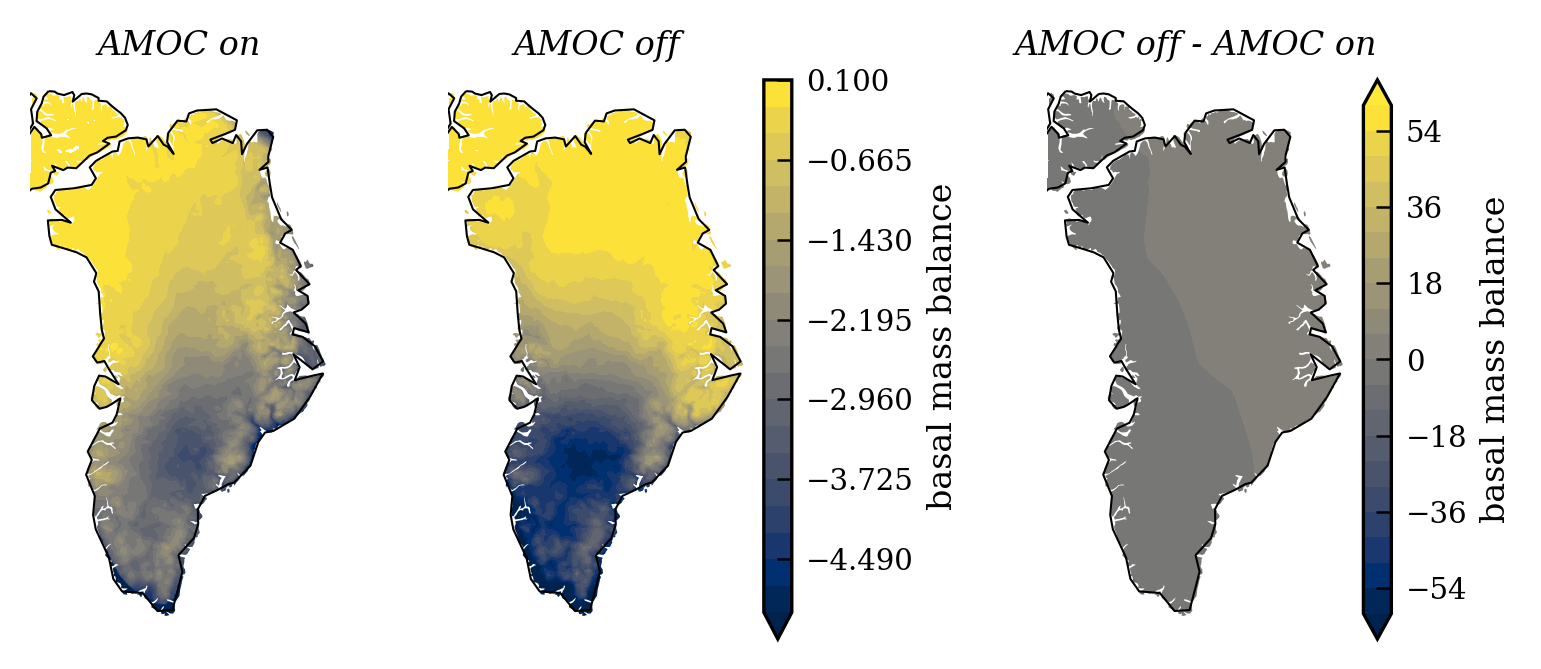

In [59]:
fig, (ax1, ax2, ax3) = plot.subplots_GIS(nrows=1, ncols=3, figsize=(plot.width_onecol*1.5, plot.height_onecol))
# plt.figure()
# ds_bmb_amoc_on["bmb_ann"].isel(time=-1).plot.pcolormesh()
# plt.figure()
# ds_bmb_amoc_off["bmb_ann"].isel(time=-1).plot.pcolormesh()
# plt.figure()
# (ds_bmb_amoc_off["bmb_ann"].isel(time=-1) - ds_bmb_amoc_on["bmb_ann"].isel(time=-1)).plot.pcolormesh()

vmin = -5
vmax = 0.1
nlevels = 21
var = "bmb_ann"
plot_BMB(ds_bmb_amoc_on, AMOC_ON, var=var, year_slice=slice(0, 1), vmin=vmin, vmax=vmax, nlevels=nlevels, fig=fig, ax=ax1, savefig=False, add_cbar=False)
plot_BMB(ds_bmb_amoc_off, AMOC_OFF, var=var, year_slice=slice(0, 1), vmin=vmin, vmax=vmax, nlevels=nlevels, fig=fig, ax=ax2, savefig=False)

# Take the differnce between the datasets, but only where both have non-zero values
ds_bmb_amoc_on_masked = ds_bmb_amoc_on.where((ds_bmb_amoc_on[var] != 0) & (ds_bmb_amoc_off[var] != 0))
ds_bmb_amoc_off_masked = ds_bmb_amoc_off.where((ds_bmb_amoc_on[var] != 0) & (ds_bmb_amoc_off[var] != 0))
ds_bmb_diff = ds_bmb_amoc_off_masked - ds_bmb_amoc_on_masked
plot_BMB(ds_bmb_diff, "diff", var=var, year_slice=slice(0, 1), vmin=-60, vmax=60, nlevels=21, extend="both", fig=fig, ax=ax3, savefig=False, add_cbar=True)

ax1.set_title("AMOC on", fontstyle='italic', fontsize=8)
ax2.set_title("AMOC off", fontstyle='italic', fontsize=8)
ax3.set_title("AMOC off - AMOC on", fontstyle='italic', fontsize=8)

### Pre-industrial

vmin = -3614.5068359375, vmax = 797.9561767578125


vmin = -1498.4871826171875, vmax = 564.723876953125
vmin = -1333.175048828125, vmax = 3554.066650390625


Text(0.5, 1.0, 'AMOC off - AMOC on')

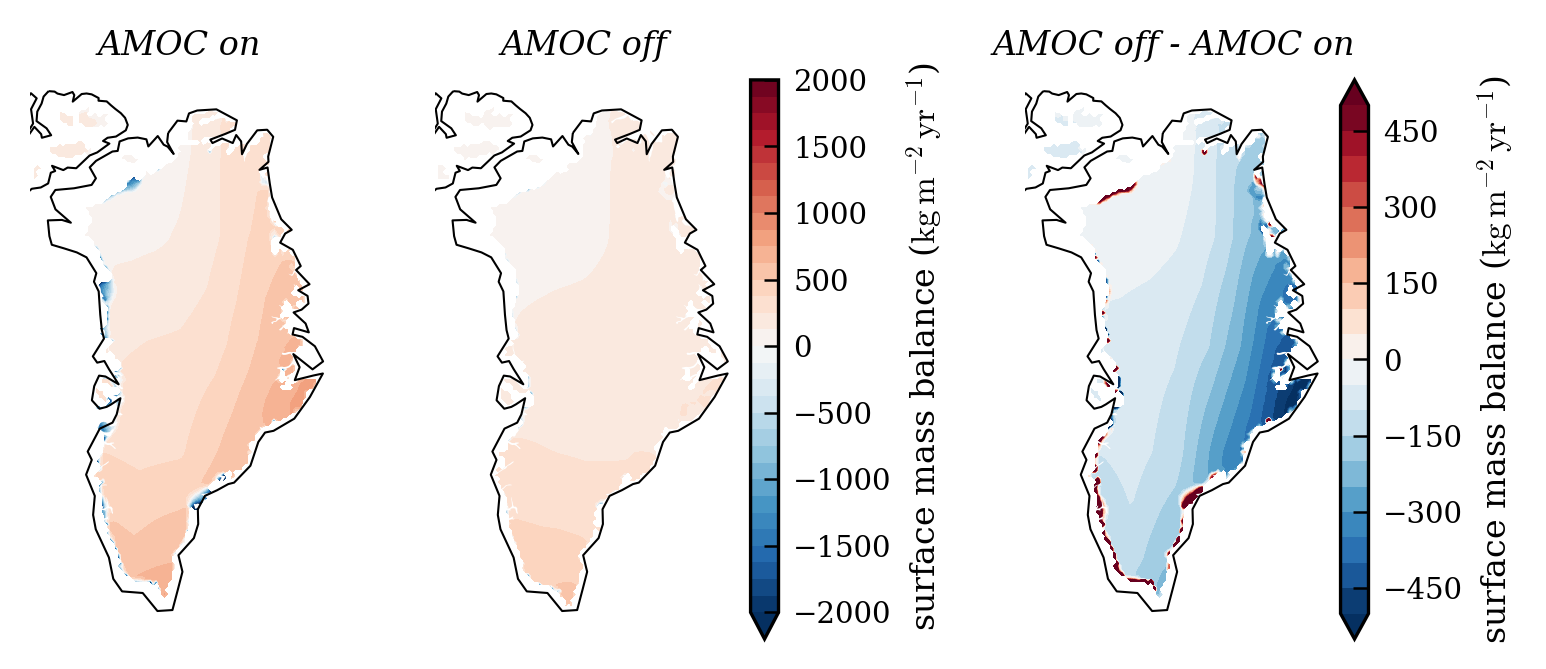

In [60]:
fig, (ax1, ax2, ax3) = plot.subplots_GIS(nrows=1, ncols=3, figsize=(plot.width_onecol*1.5, plot.height_onecol))

vmin = -2000
vmax = 2000
nlevels = 33
var = "smb_ice"
plot_SMB_smb(ds_smb_amoc_on, AMOC_ON, year_slice=slice(0, 1000), vmin=vmin, vmax=vmax, nlevels=nlevels, fig=fig, ax=ax1, savefig=False, add_cbar=False)
plot_SMB_smb(ds_smb_amoc_off, AMOC_OFF, year_slice=slice(0, 1000), vmin=vmin, vmax=vmax, nlevels=nlevels, fig=fig, ax=ax2, savefig=False)

# Take the differnce between the datasets, but only where both have non-zero values
ds_smb_amoc_on_masked = ds_smb_amoc_on.where((ds_smb_amoc_on[var] != 0) & (ds_smb_amoc_off[var] != 0))
ds_smb_amoc_off_masked = ds_smb_amoc_off.where((ds_smb_amoc_on[var] != 0) & (ds_smb_amoc_off[var] != 0))
ds_smb_diff = ds_smb_amoc_off_masked - ds_smb_amoc_on_masked
plot_SMB_smb(ds_smb_diff, "diff", var="smb_ice", year_slice=slice(0, 1000), vmin=-500, vmax=500, nlevels=21, extend="both", fig=fig, ax=ax3, savefig=False, add_cbar=True)

ax1.set_title("AMOC on", fontstyle='italic', fontsize=8)
ax2.set_title("AMOC off", fontstyle='italic', fontsize=8)
ax3.set_title("AMOC off - AMOC on", fontstyle='italic', fontsize=8)

vmin = 50.749717712402344, vmax = 934.7634887695312
Average snow_ann over time and space: 412.10 $\text{kg}\,\text{m}^{-2}\,\text{yr}^{-1}$
vmin = 44.41328048706055, vmax = 755.4222412109375
Average snow_ann over time and space: 262.14 $\text{kg}\,\text{m}^{-2}\,\text{yr}^{-1}$
vmin = -593.9609985351562, vmax = 125.4439926147461
Average snow_ann over time and space: -149.96 $\text{kg}\,\text{m}^{-2}\,\text{yr}^{-1}$
vmin = -34.423744201660156, vmax = 5.107564449310303
Average t_ground over time and space: -8.44 $\text{K}$
vmin = -38.381343841552734, vmax = 3.9576876163482666
Average t_ground over time and space: -10.67 $\text{K}$
vmin = -13.521683692932129, vmax = 9.869220733642578
Average t_ground over time and space: -2.23 $\text{K}$


Text(0.5, 1.0, 'AMOC off - AMOC on')

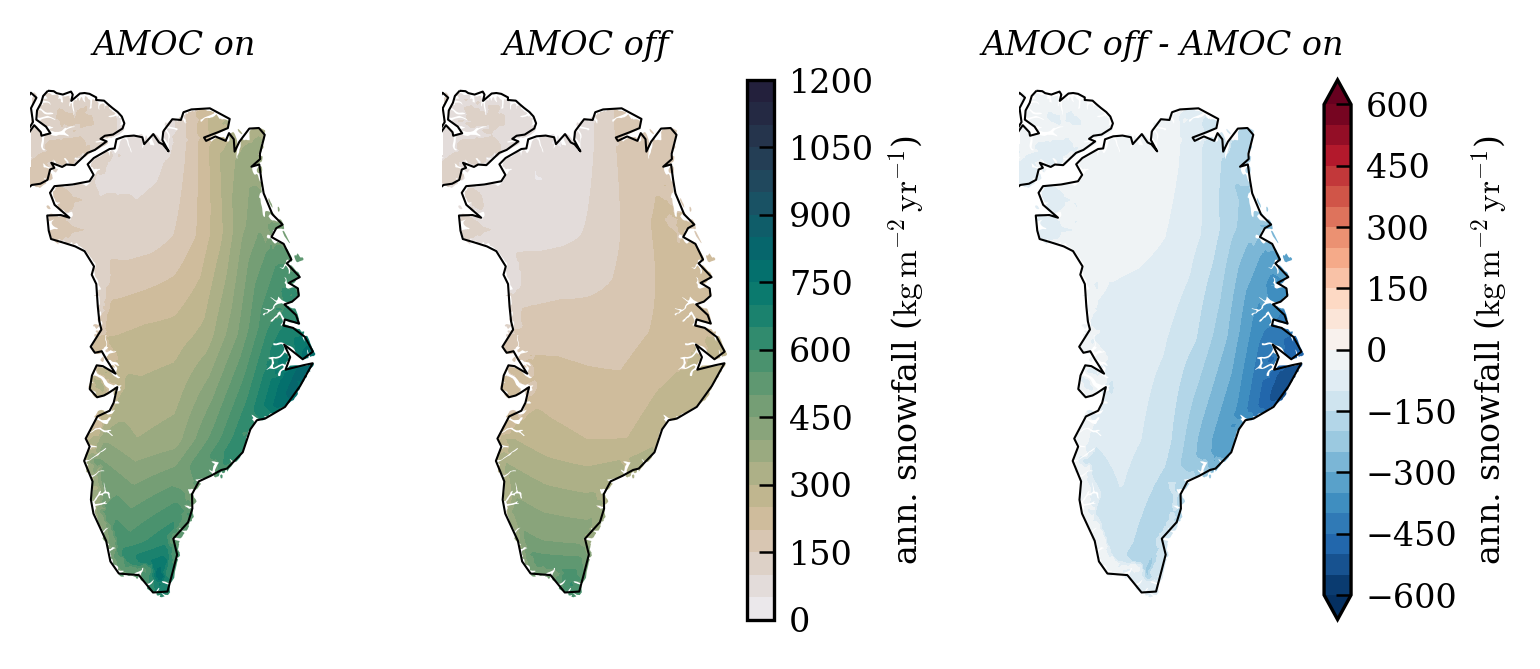

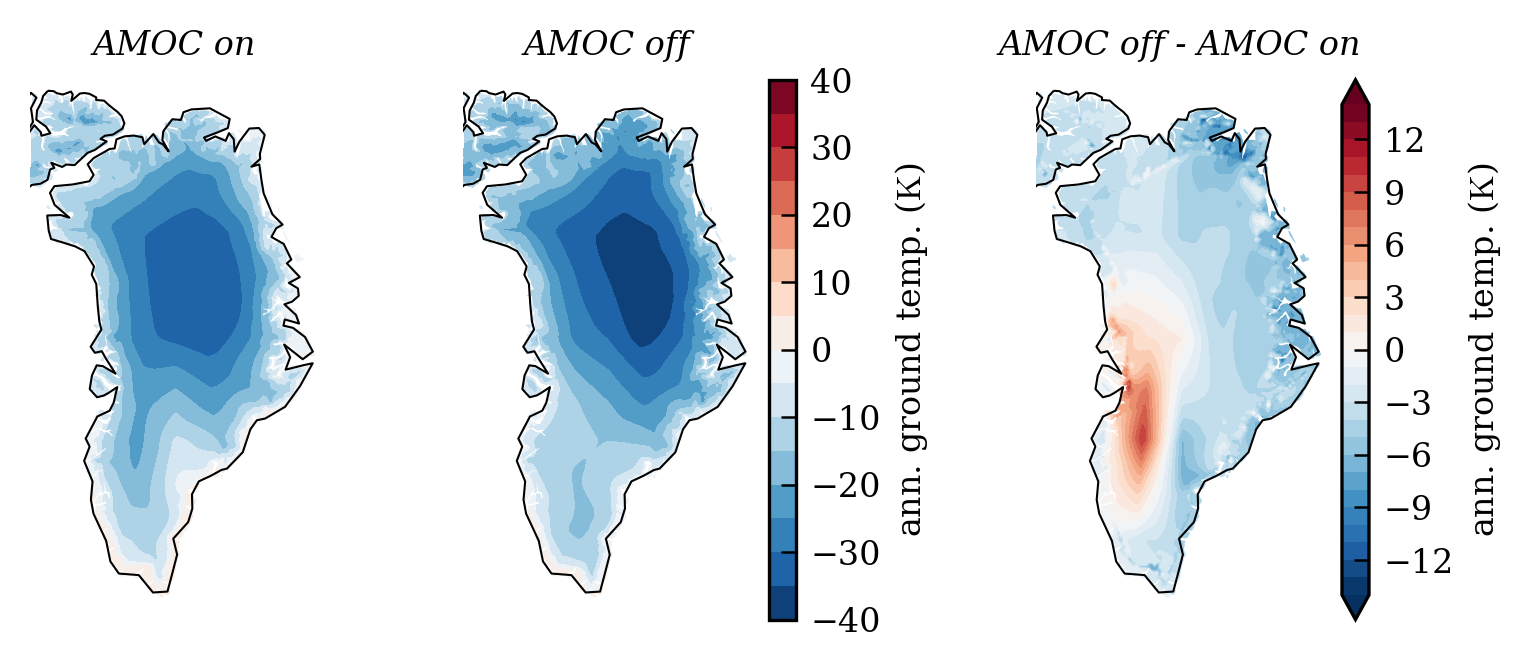

In [61]:
# Snow fall
fig, (ax1, ax2, ax3) = plot.subplots_GIS(nrows=1, ncols=3, figsize=(plot.width_onecol*1.5, plot.height_onecol))

vmin = 0
vmax = 1200
nlevels = 25
var = "snow_ann"
plot_SMB_smb_components(ds_smb_amoc_on, AMOC_ON, var=var, year_slice=slice(0, 1000), vmin=vmin, vmax=vmax, nlevels=nlevels, fig=fig, ax=ax1, savefig=False, add_cbar=False)
plot_SMB_smb_components(ds_smb_amoc_off, AMOC_OFF, var=var, year_slice=slice(0, 1000), vmin=vmin, vmax=vmax, nlevels=nlevels, fig=fig, ax=ax2, savefig=False)

# Take the differnce between the datasets, but only where both have non-zero values
ds_smb_amoc_on_masked = ds_smb_amoc_on.where((ds_smb_amoc_on[var] != 0) & (ds_smb_amoc_off[var] != 0))
ds_smb_amoc_off_masked = ds_smb_amoc_off.where((ds_smb_amoc_on[var] != 0) & (ds_smb_amoc_off[var] != 0))
ds_smb_diff = ds_smb_amoc_off_masked - ds_smb_amoc_on_masked
cmap = plt.get_cmap("RdBu_r")
plot_SMB_smb_components(ds_smb_diff, "diff", var=var, year_slice=slice(0, 1000), vmin=-600, vmax=600, nlevels=25, extend="both", cmap=cmap,fig=fig, ax=ax3, savefig=False, add_cbar=True)

ax1.set_title("AMOC on", fontstyle='italic', fontsize=8)
ax2.set_title("AMOC off", fontstyle='italic', fontsize=8)
ax3.set_title("AMOC off - AMOC on", fontstyle='italic', fontsize=8)

# Ground temperature
fig, (ax1, ax2, ax3) = plot.subplots_GIS(nrows=1, ncols=3, figsize=(plot.width_onecol*1.5, plot.height_onecol))

vmin = -40
vmax = 40
nlevels = 17
var = "t_ground"
cmap = plt.get_cmap("RdBu_r")

plot_SMB_smb_components(ds_smb_amoc_on, AMOC_ON, var=var, year_slice=slice(0, 1000), vmin=vmin, vmax=vmax, nlevels=nlevels, cmap=cmap, fig=fig, ax=ax1, savefig=False, add_cbar=False)
plot_SMB_smb_components(ds_smb_amoc_off, AMOC_OFF, var=var, year_slice=slice(0, 1000), vmin=vmin, vmax=vmax, nlevels=nlevels, cmap=cmap, fig=fig, ax=ax2, savefig=False)

# Take the differnce between the datasets, but only where both have non-zero values
ds_smb_amoc_on_masked = ds_smb_amoc_on.where((ds_smb_amoc_on[var] != 0) & (ds_smb_amoc_off[var] != 0))
ds_smb_amoc_off_masked = ds_smb_amoc_off.where((ds_smb_amoc_on[var] != 0) & (ds_smb_amoc_off[var] != 0))
ds_smb_diff = ds_smb_amoc_off_masked - ds_smb_amoc_on_masked

plot_SMB_smb_components(ds_smb_diff, "diff", var=var, year_slice=slice(0, 1000), vmin=-14, vmax=14, nlevels=29, extend="both", cmap=cmap, fig=fig, ax=ax3, savefig=False, add_cbar=True)

ax1.set_title("AMOC on", fontstyle='italic', fontsize=8)
ax2.set_title("AMOC off", fontstyle='italic', fontsize=8)
ax3.set_title("AMOC off - AMOC on", fontstyle='italic', fontsize=8)
